In [2]:
%pip install pandas numpy matplotlib seaborn scikit-learn pillow

Note: you may need to restart the kernel to use updated packages.


In [3]:
from pathlib import Path

ROOT = Path(r"E:\Projects\Deepfake detector")

patterns = [
    "*.pt", "*.pth", "*.ckpt",
    "*.json", "*.csv"
]

for folder in ["experiments", "data/metadata"]:
    base = ROOT / folder
    print(f"\n--- {folder} ---")

    if not base.exists():
        print("Folder missing")
        continue

    files = []
    for pattern in patterns:
        files.extend(base.rglob(pattern))

    for path in sorted(set(files)):
        print(path.relative_to(ROOT))


--- experiments ---
experiments\benchmark-visualizations\cifake_report_metrics.csv
experiments\fft-baseline\cifake-image-v2\cifake-fft-resnet18-best.pt
experiments\fft-baseline\cifake-image-v2\cifake-fft-resnet18-config.json
experiments\fft-baseline\cifake-image-v2\cifake-fft-resnet18-history.json
experiments\fft-baseline\cifake-image-v2\cifake-fft-resnet18-report.json
experiments\fft-baseline\cifake-image-v2\comparison-report.json
experiments\fusion-baseline\cifake-image-v2\cifake-fusion-resnet18-best.pt
experiments\fusion-baseline\cifake-image-v2\cifake-fusion-resnet18-config.json
experiments\fusion-baseline\cifake-image-v2\cifake-fusion-resnet18-history.json
experiments\fusion-baseline\cifake-image-v2\cifake-fusion-resnet18-report.json
experiments\fusion-baseline\cifake-image-v2\comparison-report.json
experiments\rgb-baseline\cifake-image-v2\cifake-rgb-resnet18-best.pt
experiments\rgb-baseline\cifake-image-v2\cifake-rgb-resnet18-config.json
experiments\rgb-baseline\cifake-image-v2\

In [4]:
import json
from pathlib import Path
import pandas as pd

MODEL_RUNS = {
    "CIFAKE RGB": (
        "experiments/rgb-baseline/cifake-image-v2",
        "cifake-rgb-resnet18",
    ),
    "CIFAKE FFT": (
        "experiments/fft-baseline/cifake-image-v2",
        "cifake-fft-resnet18",
    ),
    "CIFAKE RGB+FFT": (
        "experiments/fusion-baseline/cifake-image-v2",
        "cifake-fusion-resnet18",
    ),
    "FaceForensics++ RGB": (
        "experiments/rgb-baseline/faceforensicspp-c23-r2-v1-limited-clean",
        "faceforensicspp-rgb-resnet18",
    ),
}

for model_name, (relative_dir, prefix) in MODEL_RUNS.items():
    run_dir = ROOT / relative_dir
    print(f"\n{'=' * 65}\n{model_name}\n{'=' * 65}")

    for suffix in ["best.pt", "config.json", "history.json", "report.json"]:
        path = run_dir / f"{prefix}-{suffix}"

        if not path.exists():
            print(f"MISSING: {path.relative_to(ROOT)}")
            continue

        if suffix == "best.pt":
            print(f"Checkpoint: {path.relative_to(ROOT)}")
            print(f"Size: {path.stat().st_size / (1024**2):.2f} MiB")
            continue

        with path.open("r", encoding="utf-8") as f:
            data = json.load(f)

        print(f"\n{suffix}:")
        print(json.dumps(data, indent=2)[:5000])


CIFAKE RGB
Checkpoint: experiments\rgb-baseline\cifake-image-v2\cifake-rgb-resnet18-best.pt
Size: 42.72 MiB

config.json:
{
  "task": "cifake",
  "manifest_dir": "data\\metadata\\cifake-image-v2",
  "output_dir": "experiments\\rgb-baseline\\cifake-image-v2",
  "epochs": 1,
  "batch_size": 32,
  "learning_rate": 0.0001,
  "weight_decay": 0.0001,
  "seed": 42,
  "num_workers": 0,
  "max_records": null,
  "pretrained": true,
  "source_frame_manifest": null
}

history.json:
[
  {
    "epoch": 1,
    "train_loss": 0.22666865484756585,
    "val_loss": 0.17187808001169075,
    "val_accuracy": 0.9364844903988183
  }
]

report.json:
{
  "task": "cifake",
  "records": {
    "train": 6318,
    "val": 1354,
    "test": 1354
  },
  "class_counts": {
    "train": {
      "real": 3160,
      "fake": 3158
    },
    "val": {
      "real": 677,
      "fake": 677
    },
    "test": {
      "real": 678,
      "fake": 676
    }
  },
  "group_counts": {
    "train": 6318,
    "val": 1354,
    "test": 1354

In [5]:

import json
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

ROOT = Path(r"E:\Projects\Deepfake detector")
OUT = ROOT / "experiments" / "benchmark-visualizations"
OUT.mkdir(parents=True, exist_ok=True)

RUNS = {
    "RGB ResNet18": ROOT / "experiments/rgb-baseline/cifake-image-v2",
    "FFT ResNet18": ROOT / "experiments/fft-baseline/cifake-image-v2",
    "RGB + FFT Fusion": ROOT / "experiments/fusion-baseline/cifake-image-v2",
}

rows = []
histories = {}

for model_name, run_dir in RUNS.items():
    prefix_map = {
        "RGB ResNet18": "cifake-rgb-resnet18",
        "FFT ResNet18": "cifake-fft-resnet18",
        "RGB + FFT Fusion": "cifake-fusion-resnet18",
    }
    prefix = prefix_map[model_name]

    report_path = run_dir / f"{prefix}-report.json"
    history_path = run_dir / f"{prefix}-history.json"

    if not report_path.exists():
        print(f"Skipping missing report: {report_path}")
        continue

    report = json.loads(report_path.read_text(encoding="utf-8"))
    test = report.get("test_metrics", {})

    rows.append({
        "dataset": "CIFAKE",
        "model": model_name,
        "test_samples": report.get("records", {}).get("test"),
        "accuracy": test.get("accuracy"),
        "precision": test.get("precision"),
        "recall": test.get("recall"),
        "f1": test.get("f1"),
        "roc_auc": test.get("roc_auc"),
        "test_loss": test.get("loss"),
        "device_used_for_training": report.get("device"),
        "best_epoch": report.get("best_epoch"),
    })

    if history_path.exists():
        histories[model_name] = json.loads(
            history_path.read_text(encoding="utf-8")
        )

metrics_df = pd.DataFrame(rows)
display(metrics_df)

metrics_df.to_csv(OUT / "cifake_report_metrics.csv", index=False)
print("Saved:", OUT / "cifake_report_metrics.csv")


,dataset,model,test_samples,accuracy,precision,recall,f1,roc_auc,test_loss,device_used_for_training,best_epoch
0,CIFAKE,RGB ResNet18,1354,0.935007,NaN,NaN,NaN,NaN,0.179444,cpu,1
1,CIFAKE,FFT ResNet18,1354,0.854505,0.824966,0.899408,0.860580,0.933428,0.338781,cpu,1
2,CIFAKE,RGB + FFT Fusion,1354,0.932053,0.901099,0.970414,0.934473,0.982414,0.197226,cpu,1


Saved: E:\Projects\Deepfake detector\experiments\benchmark-visualizations\cifake_report_metrics.csv


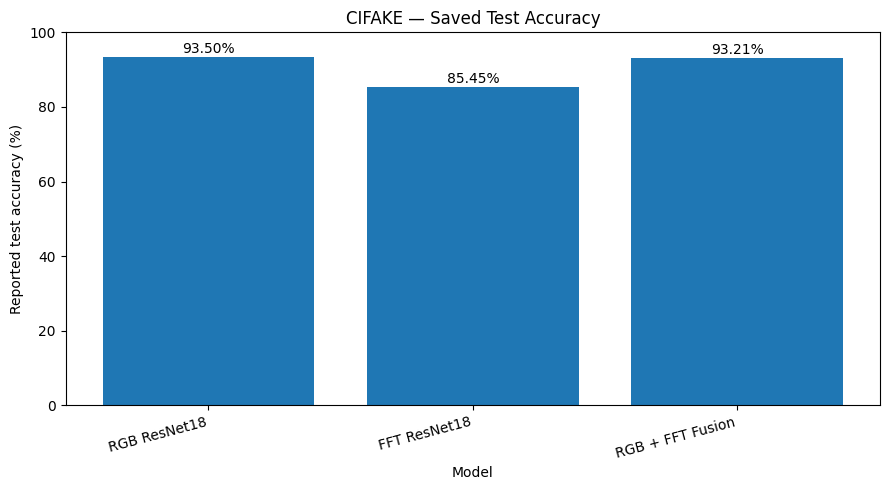

In [6]:

plot_df = metrics_df.dropna(subset=["accuracy"]).copy()

if not plot_df.empty:
    plt.figure(figsize=(9, 5))
    bars = plt.bar(plot_df["model"], plot_df["accuracy"] * 100)

    plt.ylabel("Reported test accuracy (%)")
    plt.xlabel("Model")
    plt.title("CIFAKE — Saved Test Accuracy")
    plt.ylim(0, 100)
    plt.xticks(rotation=15, ha="right")

    for bar, value in zip(bars, plot_df["accuracy"]):
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 1,
            f"{value:.2%}",
            ha="center",
        )

    plt.tight_layout()
    plt.savefig(OUT / "cifake_accuracy_comparison.png", dpi=180)
    plt.show()
else:
    print("No reported accuracy metrics found.")


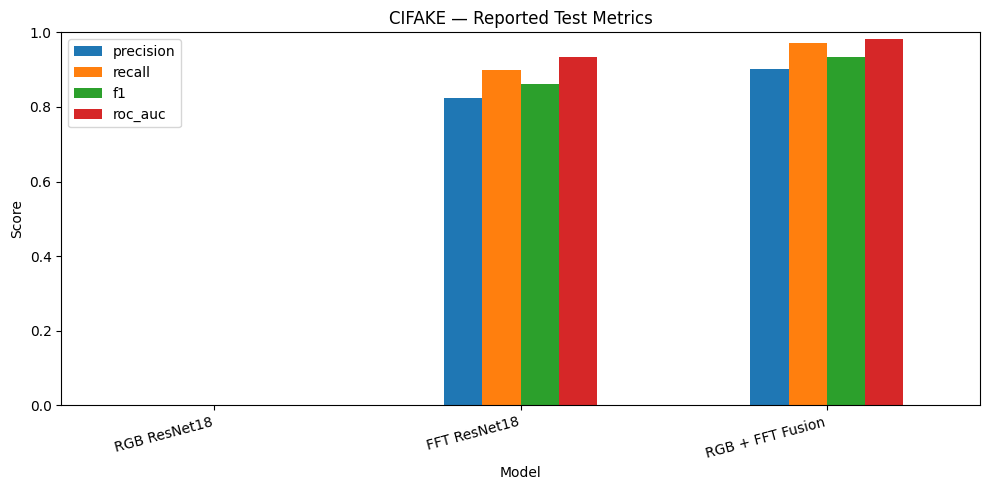

In [7]:

metric_columns = ["precision", "recall", "f1", "roc_auc"]

available = [
    col for col in metric_columns
    if col in metrics_df.columns and metrics_df[col].notna().any()
]

if available:
    ax = metrics_df.set_index("model")[available].plot(
        kind="bar", figsize=(10, 5), ylim=(0, 1)
    )
    ax.set_title("CIFAKE — Reported Test Metrics")
    ax.set_ylabel("Score")
    ax.set_xlabel("Model")
    plt.xticks(rotation=15, ha="right")
    plt.tight_layout()
    plt.savefig(OUT / "cifake_test_metrics_comparison.png", dpi=180)
    plt.show()
else:
    print("Precision, recall, F1 and ROC-AUC are not present in the saved reports.")


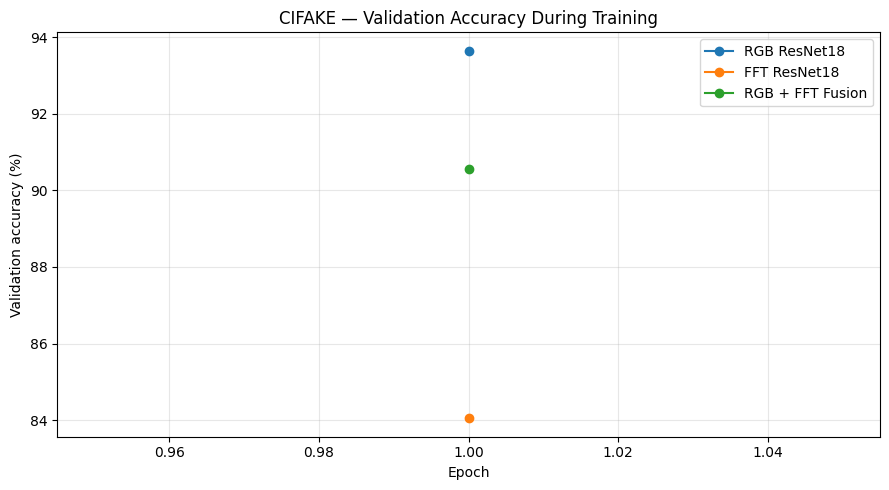

In [8]:

plt.figure(figsize=(9, 5))

for model_name, history in histories.items():
    epochs = [item["epoch"] for item in history]
    val_accuracy = []

    for item in history:
        # Some training scripts store validation accuracy directly;
        # others store it inside val_metrics.
        value = item.get("val_accuracy")
        if value is None:
            value = item.get("val_metrics", {}).get("accuracy")
        val_accuracy.append(value)

    valid = [
        (epoch, value)
        for epoch, value in zip(epochs, val_accuracy)
        if value is not None
    ]

    if valid:
        x, y = zip(*valid)
        plt.plot(x, np.array(y) * 100, marker="o", label=model_name)

plt.xlabel("Epoch")
plt.ylabel("Validation accuracy (%)")
plt.title("CIFAKE — Validation Accuracy During Training")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(OUT / "cifake_validation_accuracy_history.png", dpi=180)
plt.show()


In [9]:
from pathlib import Path

ROOT = Path(r"E:\Projects\Deepfake detector")

CHECKPOINTS = {
    "CIFAKE RGB": ROOT / "experiments/rgb-baseline/cifake-image-v2/cifake-rgb-resnet18-best.pt",
    "CIFAKE FFT": ROOT / "experiments/fft-baseline/cifake-image-v2/cifake-fft-resnet18-best.pt",
    "CIFAKE RGB+FFT": ROOT / "experiments/fusion-baseline/cifake-image-v2/cifake-fusion-resnet18-best.pt",
}

for name, path in CHECKPOINTS.items():
    print(f"{name}: {'FOUND' if path.is_file() else 'MISSING'}")
    print(f"  {path}")

CIFAKE RGB: FOUND
  E:\Projects\Deepfake detector\experiments\rgb-baseline\cifake-image-v2\cifake-rgb-resnet18-best.pt
CIFAKE FFT: FOUND
  E:\Projects\Deepfake detector\experiments\fft-baseline\cifake-image-v2\cifake-fft-resnet18-best.pt
CIFAKE RGB+FFT: FOUND
  E:\Projects\Deepfake detector\experiments\fusion-baseline\cifake-image-v2\cifake-fusion-resnet18-best.pt


In [10]:
import json

for name, path in CHECKPOINTS.items():
    if not path.is_file():
        continue

    run_dir = path.parent
    print(f"\n--- {name} ---")

    config_path = next(run_dir.glob("*-config.json"), None)
    report_path = next(run_dir.glob("*-report.json"), None)

    if config_path and config_path.is_file():
        print("CONFIG:")
        print(json.dumps(json.loads(config_path.read_text()), indent=2))

    if report_path and report_path.is_file():
        print("REPORT:")
        print(json.dumps(json.loads(report_path.read_text()), indent=2))


--- CIFAKE RGB ---
CONFIG:
{
  "task": "cifake",
  "manifest_dir": "data\\metadata\\cifake-image-v2",
  "output_dir": "experiments\\rgb-baseline\\cifake-image-v2",
  "epochs": 1,
  "batch_size": 32,
  "learning_rate": 0.0001,
  "weight_decay": 0.0001,
  "seed": 42,
  "num_workers": 0,
  "max_records": null,
  "pretrained": true,
  "source_frame_manifest": null
}
REPORT:
{
  "task": "cifake",
  "records": {
    "train": 6318,
    "val": 1354,
    "test": 1354
  },
  "class_counts": {
    "train": {
      "real": 3160,
      "fake": 3158
    },
    "val": {
      "real": 677,
      "fake": 677
    },
    "test": {
      "real": 678,
      "fake": 676
    }
  },
  "group_counts": {
    "train": 6318,
    "val": 1354,
    "test": 1354
  },
  "duplicate_records": 0,
  "source_group_leakage": [],
  "image_files_validated": 9046,
  "device": "cpu",
  "pretrained_weights_requested": true,
  "pretrained_weights_loaded": true,
  "best_checkpoint": "experiments\\rgb-baseline\\cifake-image-v2\\ci

In [11]:
%pip install ipywidgets

Note: you may need to restart the kernel to use updated packages.


In [12]:
import sys
from pathlib import Path
import torch

ROOT = Path(r"E:\Projects\Deepfake detector")

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from backend.training.rgb_baseline import build_model
from backend.training.fft_baseline import build_fft_model
from backend.training.fusion_baseline import RGBFFTFusionModel
from backend.app.preprocessing import preprocess_rgb
from backend.app.frequency import preprocess_fft

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def load_trained_model(checkpoint_path, model):
    checkpoint_path = Path(checkpoint_path)

    if not checkpoint_path.is_file():
        raise FileNotFoundError(
            f"Checkpoint not found: {checkpoint_path}"
        )

    # Use only with trusted checkpoints created by your own training pipeline.
    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=False,
    )

    if "model_state" not in checkpoint:
        raise KeyError(
            f"'model_state' missing from {checkpoint_path.name}"
        )

    model.load_state_dict(checkpoint["model_state"], strict=True)
    model = model.to(device)
    model.eval()

    print(
        f"Loaded: {checkpoint_path.name} | "
        f"epoch: {checkpoint.get('epoch', 'unknown')}"
    )
    return model


# Use CHECKPOINTS, which was defined in Cell 7.
rgb_model = load_trained_model(
    CHECKPOINTS["CIFAKE RGB"],
    build_model(pretrained=False),
)

fft_model = load_trained_model(
    CHECKPOINTS["CIFAKE FFT"],
    build_fft_model(pretrained=False)[0],
)

fusion_model = load_trained_model(
    CHECKPOINTS["CIFAKE RGB+FFT"],
    RGBFFTFusionModel(pretrained=False),
)

print("\nAll three CIFAKE models loaded successfully.")
print("Inference device:", device)

Loaded: cifake-rgb-resnet18-best.pt | epoch: 1
Loaded: cifake-fft-resnet18-best.pt | epoch: 1
Loaded: cifake-fusion-resnet18-best.pt | epoch: 1

All three CIFAKE models loaded successfully.
Inference device: cuda


In [10]:
from pathlib import Path
from IPython.display import display
from ipywidgets import FileUpload

image_picker = FileUpload(
    accept=".jpg,.jpeg,.png,.webp",
    multiple=False,
    description="Choose image"
)

display(image_picker)

FileUpload(value=(), accept='.jpg,.jpeg,.png,.webp', description='Choose image')

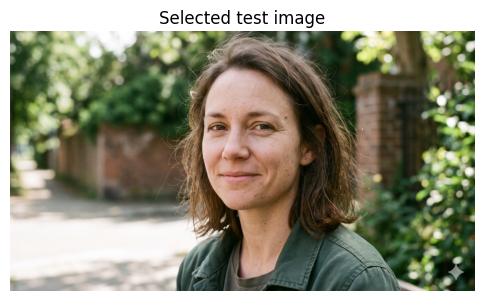

Image size: (2752, 1536)


In [11]:
from PIL import Image
from io import BytesIO
import matplotlib.pyplot as plt

def get_uploaded_image(upload_widget):
    value = upload_widget.value

    if not value:
        raise ValueError("Please select an image first.")

    # Supports common ipywidgets 7 and 8 upload formats.
    if isinstance(value, dict):
        item = next(iter(value.values()))
        content = item["content"]
    else:
        item = value[0]
        content = item["content"]

    image = Image.open(BytesIO(bytes(content))).convert("RGB")
    return image

sample_image = get_uploaded_image(image_picker)

plt.figure(figsize=(6, 6))
plt.imshow(sample_image)
plt.axis("off")
plt.title("Selected test image")
plt.show()

print("Image size:", sample_image.size)

In [14]:
from backend.app.preprocessing import preprocess_rgb
from backend.app.frequency import preprocess_fft

import numpy as np
import torch

# Use the same device variable expected by your inference cell.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("RGB preprocessing:", preprocess_rgb)
print("FFT preprocessing:", preprocess_fft)
print("Inference device:", device)

ModuleNotFoundError: No module named 'backend'

In [13]:
import time
import numpy as np
import pandas as pd
import torch
from IPython.display import display


def prepare_image_inputs(image):
    rgb = torch.from_numpy(
        np.ascontiguousarray(preprocess_rgb(image))
    ).unsqueeze(0).to(device)

    fft = torch.from_numpy(
        np.ascontiguousarray(preprocess_fft(image))
    ).unsqueeze(0).to(device)

    return rgb, fft


def predict_one(model, *inputs):
    model.eval()

    if device.type == "cuda":
        torch.cuda.synchronize()

    start = time.perf_counter()

    with torch.inference_mode():
        logits = model(*inputs)

    if device.type == "cuda":
        torch.cuda.synchronize()

    elapsed_ms = (time.perf_counter() - start) * 1000

    if tuple(logits.shape) != (1, 2):
        raise ValueError(
            f"Expected model output shape (1, 2); got {tuple(logits.shape)}"
        )

    probabilities = torch.softmax(logits, dim=1)[0].cpu()
    predicted_index = int(probabilities.argmax().item())

    # Confirmed training label order must be 0=real, 1=fake.
    labels = ["Real", "AI-generated"]

    return {
        "Predicted class": labels[predicted_index],
        "Real score (%)": round(probabilities[0].item() * 100, 2),
        "AI-generated score (%)": round(probabilities[1].item() * 100, 2),
        "Inference time (ms)": round(elapsed_ms, 2),
    }


rgb_input, fft_input = prepare_image_inputs(sample_image)

predictors = {
    "RGB": lambda: predict_one(rgb_model, rgb_input),
    "FFT": lambda: predict_one(fft_model, fft_input),
    "RGB + FFT": lambda: predict_one(
        fusion_model, rgb_input, fft_input
    ),
}

rows = []

for name, predict in predictors.items():
    try:
        rows.append({"Model": name, **predict()})
    except Exception as exc:
        print(f"{name} failed: {type(exc).__name__}: {exc}")

if rows:
    results_df = pd.DataFrame(rows)
    display(results_df)
else:
    print("No predictions were generated.")

NameError: name 'preprocess_rgb' is not defined

In [17]:
import torch
import pandas as pd
from IPython.display import display

rgb_input, fft_input = prepare_image_inputs(sample_image)

tests = {
    "RGB": (rgb_model, (rgb_input,)),
    "FFT": (fft_model, (fft_input,)),
    "RGB + FFT": (fusion_model, (rgb_input, fft_input)),
}

diagnostics = []

for name, (model, inputs) in tests.items():
    model.eval()

    with torch.inference_mode():
        logits = model(*inputs)
        probs = torch.softmax(logits, dim=1)[0].cpu()

    diagnostics.append({
        "Model": name,
        "Logit class 0": round(logits[0, 0].item(), 4),
        "Logit class 1": round(logits[0, 1].item(), 4),
        "Class 0 score (%)": round(probs[0].item() * 100, 2),
        "Class 1 score (%)": round(probs[1].item() * 100, 2),
        "Predicted index": int(probs.argmax().item()),
    })

display(pd.DataFrame(diagnostics))

,Model,Logit class 0,Logit class 1,Class 0 score (%),Class 1 score (%),Predicted index
0,RGB,-8.2562,9.4461,0.00,100.00,1
1,FFT,-1.0138,0.9883,11.90,88.10,1
2,RGB + FFT,-3.2654,3.1541,0.16,99.84,1


In [18]:
from pathlib import Path
import pandas as pd

manifest_path = ROOT / "data" / "metadata" / "cifake-image-v2" / "test.csv"

if manifest_path.exists():
    df = pd.read_csv(manifest_path)
    print("Columns:", df.columns.tolist())
    display(df.head(10))
else:
    print("Manifest not found:", manifest_path)
    print("Use the actual CIFAKE test.csv path shown in your inventory.")

Columns: ['path', 'label_name', 'label', 'group_id', 'sha256', 'width', 'height', 'format', 'split']


,path,label_name,label,group_id,sha256,width,height,format,split
0,data\metadata\cifake-image-v2\training-source\...,real,0,real/382,259bac34cccc1da7c4b67c41ef72b776fe6042c01d3e40...,32,32,JPEG,test
1,data\metadata\cifake-image-v2\training-source\...,real,0,real/1935,89fc6479cf9162d18999e882da42caab8c5f00666cd673...,32,32,JPEG,test
2,data\metadata\cifake-image-v2\training-source\...,real,0,real/3571,9280f4962eb3732a58ab6a43f80974c3db626a6f7663d2...,32,32,JPEG,test
3,data\metadata\cifake-image-v2\training-source\...,real,0,real/2705,1459e2e0e32eba085481780d80b1d388b340af91c55696...,32,32,JPEG,test
4,data\metadata\cifake-image-v2\training-source\...,real,0,real/1794,8bc0c16d0d25d1024e3c02aa30dc7cc927aad2070d4887...,32,32,JPEG,test
5,data\metadata\cifake-image-v2\training-source\...,real,0,real/3071,5871b64b4af5c934a2abd13c77c9f4432e6ec0e3978c8d...,32,32,JPEG,test
6,data\metadata\cifake-image-v2\training-source\...,real,0,real/777,a5461549ef5f25bcc7cf20a0531cbd788d926db61417fb...,32,32,JPEG,test
7,data\metadata\cifake-image-v2\training-source\...,real,0,real/3460,3a8c3de5e60a8a66792e07fd286bf717488e174100252d...,32,32,JPEG,test
8,data\metadata\cifake-image-v2\training-source\...,real,0,real/690,a256e2444adb54cc2e17ce0d15871d79757698fbb1c0a5...,32,32,JPEG,test
9,data\metadata\cifake-image-v2\training-source\...,real,0,real/1456,508ed986d6bd829276512e80b3c280f9ad53aa08c15c9d...,32,32,JPEG,test


In [19]:
manifest_path = ROOT / "data" / "metadata" / "cifake-image-v2" / "test.csv"

df = pd.read_csv(manifest_path)

print("Label mapping:")
print(
    df.groupby(["label", "label_name"])
      .size()
      .reset_index(name="count")
      .sort_values("label")
      .to_string(index=False)
)

print("\nUnique labels:", sorted(df["label"].unique()))

Label mapping:
 label label_name  count
     0       real    678
     1       fake    676

Unique labels: [np.int64(0), np.int64(1)]


In [20]:
from PIL import Image
import numpy as np
import pandas as pd
import torch

manifest_path = ROOT / "data" / "metadata" / "cifake-image-v2" / "test.csv"
df = pd.read_csv(manifest_path)

print(df.groupby(["label", "label_name"]).size())

# Select 10 examples from each class
sample_rows = pd.concat([
    df[df["label_name"] == "real"].head(10),
    df[df["label_name"] == "fake"].head(10),
], ignore_index=True)

results = []

for _, row in sample_rows.iterrows():
    image_path = ROOT / row["path"]

    if not image_path.exists():
        print("Missing image:", image_path)
        continue

    image = Image.open(image_path).convert("RGB")

    rgb_input, fft_input = prepare_image_inputs(image)

    model_inputs = {
        "RGB": (rgb_model, (rgb_input,)),
        "FFT": (fft_model, (fft_input,)),
        "RGB + FFT": (fusion_model, (rgb_input, fft_input)),
    }

    result = {
        "Actual label": row["label_name"],
        "Image": str(row["path"]),
    }

    for model_name, (model, inputs) in model_inputs.items():
        model.eval()

        with torch.inference_mode():
            logits = model(*inputs)
            prediction = int(logits.argmax(dim=1).item())

        result[model_name] = prediction

    results.append(result)

results_df = pd.DataFrame(results)
display(results_df)

label  label_name
0      real          678
1      fake          676
dtype: int64


,Actual label,Image,RGB,FFT,RGB + FFT
0,real,data\metadata\cifake-image-v2\training-source\...,0,0,0
1,real,data\metadata\cifake-image-v2\training-source\...,0,0,0
2,real,data\metadata\cifake-image-v2\training-source\...,0,1,0
3,real,data\metadata\cifake-image-v2\training-source\...,0,0,0
4,real,data\metadata\cifake-image-v2\training-source\...,0,0,0
5,real,data\metadata\cifake-image-v2\training-source\...,0,0,0
6,real,data\metadata\cifake-image-v2\training-source\...,0,0,0
7,real,data\metadata\cifake-image-v2\training-source\...,0,0,0
8,real,data\metadata\cifake-image-v2\training-source\...,0,0,0
9,real,data\metadata\cifake-image-v2\training-source\...,0,0,0


In [21]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Verify class mapping before interpreting the results
print(
    df.groupby(["label", "label_name"]).size()
      .reset_index(name="count")
      .sort_values("label")
)

actual = results_df["Actual label"].map({"real": 0, "fake": 1})

for model_name in ["RGB", "FFT", "RGB + FFT"]:
    predicted = results_df[model_name]

    print(f"\n--- {model_name} ---")
    print("Accuracy:", round(accuracy_score(actual, predicted), 3))
    print("Confusion matrix (real=0, fake=1):")
    print(confusion_matrix(actual, predicted, labels=[0, 1]))
    print(classification_report(
        actual,
        predicted,
        labels=[0, 1],
        target_names=["Real", "AI-generated"],
        zero_division=0,
    ))

   label label_name  count
0      0       real    678
1      1       fake    676

--- RGB ---
Accuracy: 1.0
Confusion matrix (real=0, fake=1):
[[10  0]
 [ 0 10]]
              precision    recall  f1-score   support

        Real       1.00      1.00      1.00        10
AI-generated       1.00      1.00      1.00        10

    accuracy                           1.00        20
   macro avg       1.00      1.00      1.00        20
weighted avg       1.00      1.00      1.00        20


--- FFT ---
Accuracy: 0.95
Confusion matrix (real=0, fake=1):
[[ 9  1]
 [ 0 10]]
              precision    recall  f1-score   support

        Real       1.00      0.90      0.95        10
AI-generated       0.91      1.00      0.95        10

    accuracy                           0.95        20
   macro avg       0.95      0.95      0.95        20
weighted avg       0.95      0.95      0.95        20


--- RGB + FFT ---
Accuracy: 0.9
Confusion matrix (real=0, fake=1):
[[10  0]
 [ 2  8]]
              p

In [22]:
from PIL import Image
import pandas as pd

print("Original image size:", sample_image.size)
print("Original image mode:", sample_image.mode)

resized_image = sample_image.convert("RGB").resize(
    (224, 224),
    Image.Resampling.BILINEAR,
)

comparison = []

for image_name, image in [
    ("Original upload", sample_image),
    ("Resized to 224x224", resized_image),
]:
    rgb_input, fft_input = prepare_image_inputs(image)

    for model_name, model, inputs in [
        ("RGB", rgb_model, (rgb_input,)),
        ("FFT", fft_model, (fft_input,)),
        ("RGB + FFT", fusion_model, (rgb_input, fft_input)),
    ]:
        model.eval()

        with torch.inference_mode():
            logits = model(*inputs)
            probabilities = torch.softmax(logits, dim=1)[0].cpu()

        comparison.append({
            "Image": image_name,
            "Model": model_name,
            "Real score (%)": round(probabilities[0].item() * 100, 2),
            "AI-generated score (%)": round(probabilities[1].item() * 100, 2),
        })

display(pd.DataFrame(comparison))

Original image size: (293, 515)
Original image mode: RGB


,Image,Model,Real score (%),AI-generated score (%)
0,Original upload,RGB,0.00,100.00
1,Original upload,FFT,11.90,88.10
2,Original upload,RGB + FFT,0.16,99.84
3,Resized to 224x224,RGB,0.00,100.00
4,Resized to 224x224,FFT,11.90,88.10
5,Resized to 224x224,RGB + FFT,0.16,99.84


In [23]:
from pathlib import Path
from PIL import Image
from torch.utils.data import DataLoader, Dataset
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
)
import numpy as np
import pandas as pd
import torch


class CIFAKETestDataset(Dataset):
    def __init__(self, dataframe, root):
        self.df = dataframe.reset_index(drop=True)
        self.root = Path(root)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]
        path = self.root / row["path"]

        image = Image.open(path).convert("RGB")
        rgb, fft = prepare_image_inputs(image)

        return (
            rgb.squeeze(0),
            fft.squeeze(0),
            int(row["label"]),
        )


manifest_path = ROOT / "data" / "metadata" / "cifake-image-v2" / "test.csv"
test_df = pd.read_csv(manifest_path)

print("Test samples:", len(test_df))
print(test_df.groupby(["label", "label_name"]).size())

test_dataset = CIFAKETestDataset(test_df, ROOT)
test_loader = DataLoader(test_dataset, batch_size=8, shuffle=False)

models = {
    "RGB": rgb_model,
    "FFT": fft_model,
    "RGB + FFT": fusion_model,
}

all_results = {name: {"y": [], "pred": [], "score": []} for name in models}

for model in models.values():
    model.eval()

with torch.inference_mode():
    for rgb, fft, labels in test_loader:
        rgb = rgb.to(device)
        fft = fft.to(device)

        inputs_by_model = {
            "RGB": (rgb,),
            "FFT": (fft,),
            "RGB + FFT": (rgb, fft),
        }

        for name, model in models.items():
            logits = model(*inputs_by_model[name])
            probabilities = torch.softmax(logits, dim=1)

            all_results[name]["y"].extend(labels.tolist())
            all_results[name]["pred"].extend(
                logits.argmax(dim=1).cpu().tolist()
            )
            all_results[name]["score"].extend(
                probabilities[:, 1].cpu().tolist()
            )

summary = []

for name, result in all_results.items():
    y = np.asarray(result["y"])
    pred = np.asarray(result["pred"])
    score = np.asarray(result["score"])

    summary.append({
        "Model": name,
        "Accuracy (%)": round(accuracy_score(y, pred) * 100, 2),
        "ROC-AUC": round(roc_auc_score(y, score), 4),
    })

    print(f"\n===== {name} =====")
    print("Confusion matrix (rows=actual, columns=predicted):")
    print(confusion_matrix(y, pred, labels=[0, 1]))
    print(classification_report(
        y,
        pred,
        labels=[0, 1],
        target_names=["Real", "AI-generated"],
        zero_division=0,
    ))

display(pd.DataFrame(summary))

Test samples: 1354
label  label_name
0      real          678
1      fake          676
dtype: int64

===== RGB =====
Confusion matrix (rows=actual, columns=predicted):
[[617  61]
 [ 27 649]]
              precision    recall  f1-score   support

        Real       0.96      0.91      0.93       678
AI-generated       0.91      0.96      0.94       676

    accuracy                           0.94      1354
   macro avg       0.94      0.94      0.93      1354
weighted avg       0.94      0.94      0.93      1354


===== FFT =====
Confusion matrix (rows=actual, columns=predicted):
[[549 129]
 [ 68 608]]
              precision    recall  f1-score   support

        Real       0.89      0.81      0.85       678
AI-generated       0.82      0.90      0.86       676

    accuracy                           0.85      1354
   macro avg       0.86      0.85      0.85      1354
weighted avg       0.86      0.85      0.85      1354


===== RGB + FFT =====
Confusion matrix (rows=actual, columns=pr

,Model,Accuracy (%),ROC-AUC
0,RGB,93.50,0.9833
1,FFT,85.45,0.9334
2,RGB + FFT,93.21,0.9824
